# Two L-method variants with a shared breakpoint

This experiment compares the two descriptions supplied by the user:

- **Two affine lines:** independently fit an affine head on $k=1,\ldots,q+1$ and an affine tail on $k=q+1,\ldots,K$.
- **Affine + constant:** independently fit the same affine head and a constant tail on $k=q+1,\ldots,K$.

Both use least squares and share the observed point at $k=q+1$. Sharing an observation does not impose equality of the fitted values there. No continuity, sign, or order penalty is imposed. The selected AR order is the candidate $q$, while $q+1$ is the estimated plateau onset. The candidate set is $q=1,\ldots,K-2$, ensuring at least two observations per segment. This makes order one admissible for both methods. The descriptions' range $q=1,\ldots,K$ would include empty or undefined tails.

The main score is the segment-size-weighted RMSE:
$$S(q)=\frac{q+1}{K+1}\operatorname{RMSE}_{\rm head}(q)+\frac{K-q}{K+1}\operatorname{RMSE}_{\rm tail}(q).$$
The shared point is counted in both segments, so their sizes sum to $K+1$. This is an adaptation of the weighting principle in [Salvador and Chan (2004), Section 3.2](https://cs.fit.edu/~pkc/papers/ictai04salvador.pdf); their original construction uses disjoint segments. It is also the scoring rule used by the existing affine-plus-constant selector in `L_method.py`.

Because “best fit” does not uniquely specify a score, a sensitivity comparison uses total squared error over the same two segments, also counting the shared point twice. Exact ties favor the smaller order. All results are comparisons on simulated data, not consistency guarantees.

In [1]:
import sys
import json
import hashlib
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

PROJECT_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)
                    if (root / "Code/Code_AR_processes/L_method.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Code.Code_AR_processes.functions import jones_ar_coefficients, simulate_uniform_ar
from Code.Code_AR_processes.descent import batched_geometric_width_curves
from Code.Code_AR_processes.L_method import shared_breakpoint_l_method_selector

NAME = "ar_shared_breakpoint_l_methods"
AR_DIR = PROJECT_ROOT / "Code/Code_AR_processes"
CSV_DIR = AR_DIR / "outputs/csv" / NAME
FIGURE_DIR = AR_DIR / "outputs/images" / NAME
PDF_DIR = AR_DIR / "outputs/pdfs" / NAME
for directory in (CSV_DIR, FIGURE_DIR, PDF_DIR):
    directory.mkdir(parents=True, exist_ok=True)
settings = {
    "replications_per_order": 50, "sample_size": 2000, "burnin": 1000,
    "half_width": 1.0, "k_values": list(range(1, 11)),
    "seeds": {"1": 20260813, "2": 20260814, "3": 20260816},
    "starts": 3, "iterations": 500, "initial_step": 0.2, "geometric_decay": 0.99,
    "width_source_hashes": {
        name: hashlib.sha256((AR_DIR / name).read_bytes()).hexdigest()
        for name in ("functions.py", "descent.py")
    },
}
k_values = np.array(settings["k_values"])
print("50 processes per true order; T=2000; K=10; uniform innovations; shared breakpoint.")

50 processes per true order; T=2000; K=10; uniform innovations; shared breakpoint.


## Paired simulation

The seed families and width-optimizer settings match the preceding order-selection experiments in `ar_order_minimum_width.ipynb`: 50 independently parameterized AR processes per true order 1, 2, and 3; retained sample size 2,000; burn-in 1,000; uniform innovations on [-1,1]; three optimizer starts; 500 iterations; step sizes $0.2(0.99)^t$; and $k=1,\ldots,10$. Both methods use exactly the same estimated width curve for each replication. Cached curves are reused only if the settings and width-generator source hashes match.

In [2]:
configuration_path = CSV_DIR / "configuration.json"
width_path = CSV_DIR / "width_curves.csv"
use_cache = (configuration_path.is_file() and width_path.is_file()
             and json.loads(configuration_path.read_text()) == settings)
expected_count = 3 * settings["replications_per_order"] * len(k_values)
if use_cache:
    width_curves = pd.read_csv(width_path)
    use_cache = (len(width_curves) == expected_count
                 and not width_curves.duplicated(["true_order", "replication", "k"]).any())
if not use_cache:
    rows = []
    started = perf_counter()
    with threadpool_limits(limits=1):
        for true_order in (1, 2, 3):
            seed = settings["seeds"][str(true_order)]
            for replication in range(settings["replications_per_order"]):
                rng = np.random.default_rng(np.random.SeedSequence([seed, replication, 0]))
                phi = jones_ar_coefficients(true_order, rng=rng)
                series = simulate_uniform_ar(
                    phi, settings["sample_size"], settings["burnin"], settings["half_width"], rng=rng)
                _, widths, _ = batched_geometric_width_curves(
                    series, k_values, seed=seed, replication=replication,
                    starts=settings["starts"], iterations=settings["iterations"],
                    initial_step=settings["initial_step"], geometric_decay=settings["geometric_decay"])
                for k, width in zip(k_values, widths):
                    rows.append({"true_order": true_order, "replication": replication + 1,
                                 "k": int(k), "minimum_width": float(width),
                                 "coefficients": json.dumps(phi.tolist())})
                if (replication + 1) % 10 == 0:
                    print(f"Completed {replication + 1}/50 AR({true_order}) curves", flush=True)
    width_curves = pd.DataFrame(rows)
    width_curves.to_csv(width_path, index=False)
    configuration_path.write_text(json.dumps(settings, indent=2) + "\n")
    print(f"Generated curves in {perf_counter() - started:.1f} seconds")
else:
    print("Reused all 150 cached width curves.")
assert len(width_curves) == expected_count
assert np.isfinite(width_curves["minimum_width"]).all()

Reused all 150 cached width curves.


In [3]:
methods = {"Two affine lines": "affine", "Affine + constant": "constant"}
selection_rows, candidate_frames = [], []
for (true_order, replication), curve in width_curves.groupby(["true_order", "replication"]):
    curve = curve.sort_values("k")
    for criterion in ("weighted_rmse", "squared_error"):
        for method, tail_model in methods.items():
            fit = shared_breakpoint_l_method_selector(
                curve["k"].to_numpy(), curve["minimum_width"].to_numpy(),
                tail_model=tail_model, score_criterion=criterion)
            selection_rows.append({
                "true_order": int(true_order), "replication": int(replication),
                "method": method, "score_criterion": criterion,
                "selected_order": fit["selected_order"], "plateau_onset": fit["selected_q"],
                "score": fit["score"], "tail_slope": fit["tail_slope"],
            })
            candidate_frames.append(fit["candidate_scores"].assign(
                true_order=true_order, replication=replication, method=method, score_criterion=criterion))
selections = pd.DataFrame(selection_rows)
selections.to_csv(CSV_DIR / "selections.csv", index=False)
pd.concat(candidate_frames, ignore_index=True).to_csv(CSV_DIR / "candidate_scores.csv", index=False)
summary_rows = []
for (criterion, method, true_order), group in selections.groupby(["score_criterion", "method", "true_order"]):
    summary_rows.append({
        "score_criterion": criterion, "method": method, "true_order": int(true_order),
        "correct": int((group.selected_order == true_order).sum()),
        "under": int((group.selected_order < true_order).sum()),
        "over": int((group.selected_order > true_order).sum()), "total": len(group),
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(CSV_DIR / "summary.csv", index=False)
for criterion in ("weighted_rmse", "squared_error"):
    print(f"\n{criterion}: correct (under/over), out of 50")
    block = summary[summary.score_criterion == criterion].copy()
    block["entry"] = block.apply(lambda row: f"{row.correct}/50 ({row.under}/{row.over})", axis=1)
    print(block.pivot(index="method", columns="true_order", values="entry").reindex(methods).to_string())
paired = selections.pivot(index=["score_criterion", "true_order", "replication"],
                          columns="method", values="selected_order").reset_index()
paired.to_csv(CSV_DIR / "paired_selections.csv", index=False)
paired_rows = []
for (criterion, true_order), group in paired.groupby(["score_criterion", "true_order"]):
    a = group["Two affine lines"] == true_order
    b = group["Affine + constant"] == true_order
    paired_rows.append({"score_criterion": criterion, "true_order": int(true_order),
                        "both_correct": int((a & b).sum()), "only_two_affine_correct": int((a & ~b).sum()),
                        "only_affine_constant_correct": int((~a & b).sum()), "neither_correct": int((~a & ~b).sum())})
pd.DataFrame(paired_rows).to_csv(CSV_DIR / "paired_accuracy.csv", index=False)


weighted_rmse: correct (under/over), out of 50
true_order                   1             2             3
method                                                    
Two affine lines   49/50 (0/1)  39/50 (11/0)  19/50 (30/1)
Affine + constant  49/50 (0/1)  40/50 (10/0)  19/50 (29/2)

squared_error: correct (under/over), out of 50
true_order                   1             2             3
method                                                    
Two affine lines   49/50 (0/1)  36/50 (14/0)  18/50 (32/0)
Affine + constant  49/50 (0/1)  37/50 (13/0)  18/50 (31/1)


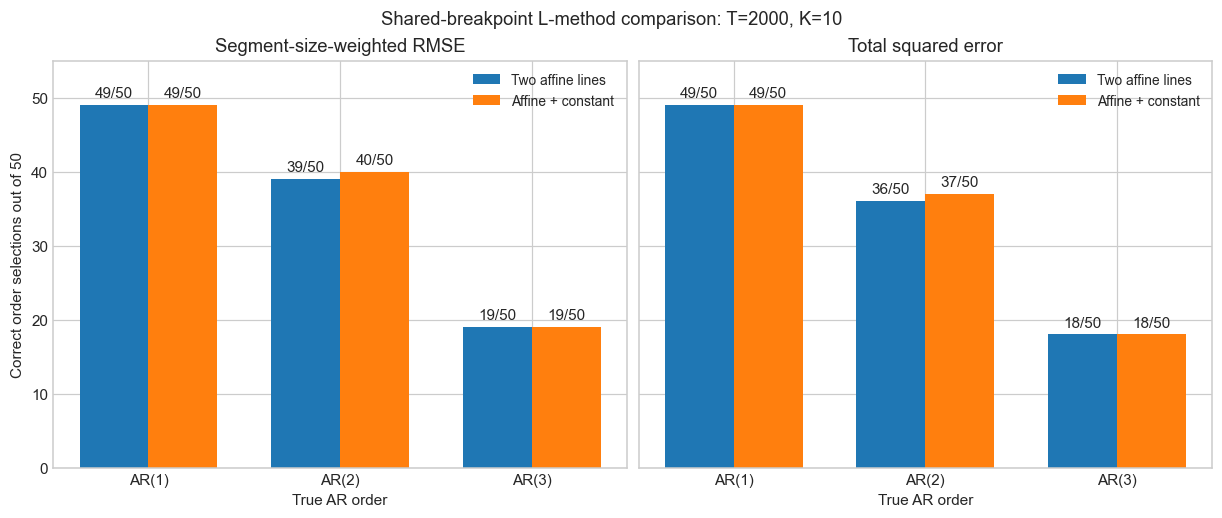

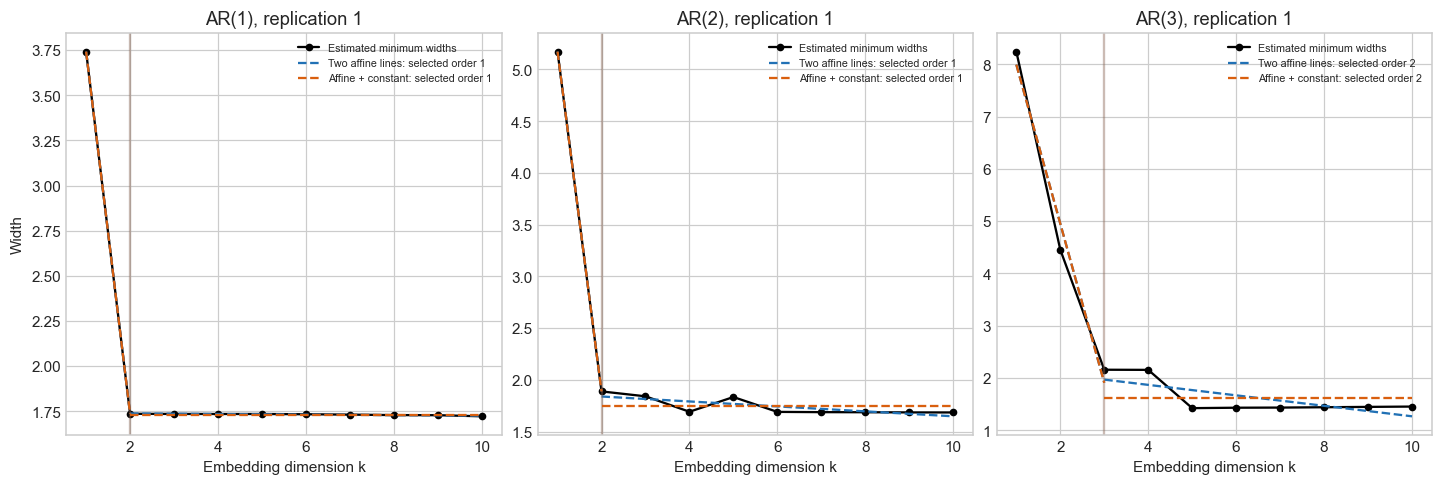

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained", sharey=True)
for axis, criterion, title in zip(axes, ("weighted_rmse", "squared_error"),
                                  ("Segment-size-weighted RMSE", "Total squared error")):
    x = np.arange(3)
    for method_index, method in enumerate(methods):
        counts = summary[(summary.score_criterion == criterion) & (summary.method == method)].sort_values("true_order").correct.to_numpy()
        bars = axis.bar(x + (method_index - 0.5) * .36, counts, .36, label=method)
        axis.bar_label(bars, labels=[f"{count}/50" for count in counts], padding=3)
    axis.set(title=title, xlabel="True AR order", xticks=x,
             xticklabels=["AR(1)", "AR(2)", "AR(3)"], ylim=(0, 55))
    axis.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Correct order selections out of 50")
fig.suptitle("Shared-breakpoint L-method comparison: T=2000, K=10")
fig.savefig(FIGURE_DIR / "accuracy.png", dpi=180)
fig.savefig(PDF_DIR / "accuracy.pdf")
plt.show()

# One example per true order, using the same observed curve for both fits.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), layout="constrained")
for axis, true_order in zip(axes, (1, 2, 3)):
    curve = width_curves[(width_curves.true_order == true_order) & (width_curves.replication == 1)].sort_values("k")
    axis.plot(curve.k, curve.minimum_width, "o-", color="black", label="Estimated minimum widths", markersize=4)
    for method, tail_model in methods.items():
        fit = shared_breakpoint_l_method_selector(curve.k, curve.minimum_width, tail_model=tail_model)
        color = "#2171b5" if tail_model == "affine" else "#d95f0e"
        axis.plot(fit["head_k"], fit["head_fitted_values"], "--", color=color,
                  label=f"{method}: selected order {fit['selected_order']}")
        axis.plot(fit["tail_k"], fit["tail_fitted_values"], "--", color=color)
        axis.axvline(fit["selected_q"], color=color, alpha=.25)
    axis.set(title=f"AR({true_order}), replication 1", xlabel="Embedding dimension k")
    axis.legend(fontsize=7)
axes[0].set_ylabel("Width")
fig.savefig(FIGURE_DIR / "example_fits.png", dpi=180)
fig.savefig(PDF_DIR / "example_fits.pdf")
plt.show()

## Results and interpretation

The following entries are correct selections out of 50, followed by (underselections/overselections).

| Main score: weighted RMSE | AR(1) | AR(2) | AR(3) | Correct total |
|---|---:|---:|---:|---:|
| Two affine lines | 49/50 (0/1) | 39/50 (11/0) | 19/50 (30/1) | 107/150 |
| Affine + constant | 49/50 (0/1) | 40/50 (10/0) | 19/50 (29/2) | 108/150 |

| Sensitivity score: total squared error | AR(1) | AR(2) | AR(3) | Correct total |
|---|---:|---:|---:|---:|
| Two affine lines | 49/50 (0/1) | 36/50 (14/0) | 18/50 (32/0) | 103/150 |
| Affine + constant | 49/50 (0/1) | 37/50 (13/0) | 18/50 (31/1) | 104/150 |

These tables are calculated in the cells above and exported to `outputs/csv/ar_shared_breakpoint_l_methods/summary.csv`. The paired correctness tables show that the affine-plus-constant method corrects exactly one AR(2) failure and introduces no new incorrect selections for either score. All AR(1) and AR(3) correctness outcomes agree, although some incorrect selected orders differ. The difference of one process gives little practical evidence of an advantage in this experiment.

My interpretation is that forcing the fitted tail to be horizontal has little effect on order recovery for these settings. Both methods frequently underselect AR(3). They share the same straight-line approximation before the candidate breakpoint; the experiment does not establish that this model-shape assumption is valid for every AR population width curve. This is an empirical observation on one fixed design and seed family, not a general performance guarantee.

This comparison uses the independent overlapping fits described by the user. The historical Table 2.1 instead used the continuous hinge model $c+s(q-k)_+$, $s\ge0$, fitted by LAD. Its results should not be substituted for this comparison.

## A schematic limitation of the plateau assumption

The following is an original constructed example, **not a verified AR population width curve**. It demonstrates that the bare condition of a constant tail after the true kink, with larger widths before it, is insufficient to guarantee either selector locates that kink. For $m=(9,6,2.6,1.6,1.6,1.6)$ the plateau starts at $k=4$, so the target order is $p=3$. Both methods choose $q=2$ under both scoring rules. An extra assumption about the pre-plateau shape or a separate correctness result would therefore be needed for a universal guarantee based solely on the plateau condition.


In [5]:
schematic_k = np.arange(1, 7)
schematic_widths = np.array([9., 6., 2.6, 1.6, 1.6, 1.6])
for criterion in ("weighted_rmse", "squared_error"):
    for method, tail_model in methods.items():
        fit = shared_breakpoint_l_method_selector(
            schematic_k, schematic_widths, tail_model=tail_model, score_criterion=criterion)
        print(f"{criterion}, {method}: selected order {fit['selected_order']}; target order 3")


weighted_rmse, Two affine lines: selected order 2; target order 3
weighted_rmse, Affine + constant: selected order 2; target order 3
squared_error, Two affine lines: selected order 2; target order 3
squared_error, Affine + constant: selected order 2; target order 3
